# TA-EVRP: Why SARSA underperforms Dijkstra — Diagnostic Analysis

This notebook diagnoses why the SARSA policy (ff58b1a9), which outperforms Dijkstra in standalone
TRSP testing, produces a higher makespan when used as the local planner in TA-EVRP.

**Runs compared:**
- `heuristic_dijkstra_20260429_115559` — ALNS outer plan + Dijkstra local routing
- `heuristic_sarsa_20260429_115803`   — ALNS outer plan + SARSA RL local routing (policy `ff58b1a9`)

**Key finding (spoiler):** the policy's routing choices are correct and identical to standalone TRSP;
the performance reversal stems from a **vehicle speed cap mismatch** between training (110 km/h) and
TA-EVRP execution (40 mph ≈ 64.4 km/h), which collapses the fast-edge speed advantage the policy was
trained to exploit.

In [1]:
import json
import csv
import sys
import random as _random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ---------- paths -----------------------------------------------------------
ROOT = Path("..")          # repository root (notebook lives in notebooks/)

DIJ_DIR  = ROOT / "runs/ta_evrp/heuristic_dijkstra_20260429_115559"
SARSA_DIR = ROOT / "runs/ta_evrp/heuristic_sarsa_20260429_115803"
TRSP_CSV  = ROOT / "runs/trsp/ff58b1a9/test_0/simulation_results.csv"
POLICY_CFG = ROOT / "runs/trsp/ff58b1a9/config.yaml"
NET_XML   = ROOT / "data/grid_road/grid_road.net.xml"

# ---------- loaders ---------------------------------------------------------
def load_json(p): return json.loads(Path(p).read_text())

dij_metrics    = load_json(DIJ_DIR  / "sim_metrics.json")
sarsa_metrics  = load_json(SARSA_DIR / "sim_metrics.json")
dij_routes     = load_json(DIJ_DIR  / "local_routes.json")
sarsa_routes   = load_json(SARSA_DIR / "local_routes.json")
dij_stops      = load_json(DIJ_DIR  / "planned_stops.json")
sarsa_stops    = load_json(SARSA_DIR / "planned_stops.json")

# TRSP standalone test results
trsp_rows = []
with open(TRSP_CSV) as f:
    for row in csv.DictReader(f):
        trsp_rows.append(row)

print("Loaded all data sources.")

Loaded all data sources.


## 1 — High-level metrics

In [2]:
rows = []
for label, m in [("Dijkstra", dij_metrics), ("SARSA ff58b1a9", sarsa_metrics)]:
    row = {"agent": label, "makespan_s": m["makespan_s"]}
    for vid, v in m["per_vehicle"].items():
        row[f"V{vid}_finish_s"] = v["finish_time_s"]
    rows.append(row)

df_metrics = pd.DataFrame(rows).set_index("agent")
display(df_metrics)

delta = sarsa_metrics["makespan_s"] - dij_metrics["makespan_s"]
print(f"\nMakespan delta: SARSA − Dijkstra = +{delta:.0f} s  ({delta/dij_metrics['makespan_s']*100:.1f}% slower)")

,makespan_s,V1_finish_s,V2_finish_s,V3_finish_s
agent,,,,
Dijkstra,524.0,524.0,521.0,478.0
SARSA ff58b1a9,556.0,523.0,556.0,481.0



Makespan delta: SARSA − Dijkstra = +32 s  (6.1% slower)


## 2 — Planned stops are identical (same EVRP plan, different local routing)

In [3]:
def stops_summary(stops_json):
    rows = []
    for v in stops_json["vehicles"]:
        for s in v["stops"]:
            rows.append({"vehicle": v["vehicle_id"], "stop_idx": s["stop_idx"],
                         "node_name": s["node_name"], "node_type": s["node_type"],
                         "sumo_node": s["sumo_node_id"]})
    return pd.DataFrame(rows)

df_dij_stops   = stops_summary(dij_stops)
df_sarsa_stops = stops_summary(sarsa_stops)

stops_match = df_dij_stops[["vehicle","stop_idx","sumo_node"]].equals(
              df_sarsa_stops[["vehicle","stop_idx","sumo_node"]])

print(f"Planned stops identical between both runs: {stops_match}")
display(df_dij_stops)

Planned stops identical between both runs: True


,vehicle,stop_idx,node_name,node_type,sumo_node
0,1,0,D,depot,C2
1,1,1,C2,customer,C3
2,1,2,C6,customer,B3
3,1,3,C5,customer,A4
4,1,4,D,depot,C2
5,2,0,D,depot,C2
6,2,1,C9,customer,B1
7,2,2,C3,customer,A1
8,2,3,C8,customer,B0
9,2,4,D,depot,C2


## 3 — Local route comparison: which legs diverge?

In [4]:
def legs_dataframe(routes_json, label):
    rows = []
    for v in routes_json["vehicles"]:
        vid = v["vehicle_id"]
        for leg in v["legs"]:
            rows.append({
                "agent":        label,
                "vehicle":      vid,
                "leg_idx":      leg["leg_idx"],
                "from_node":    leg["from_sumo_node_id"],
                "to_node":      leg["to_sumo_node_id"],
                "start_time_s": leg["start_time_s"],
                "planner_kind": leg["planner_kind"],
                "node_path":    " → ".join(leg["node_ids"]) if leg["node_ids"] else "",
                "edge_path":    ";".join(leg["edge_ids"]) if leg["edge_ids"] else "",
                "fallback":     leg.get("fallback_reason"),
            })
    return pd.DataFrame(rows)

df_dij_legs   = legs_dataframe(dij_routes, "Dijkstra")
df_sarsa_legs = legs_dataframe(sarsa_routes, "SARSA")

# Merge on vehicle+leg_idx to find differences
df_merge = df_dij_legs.merge(
    df_sarsa_legs,
    on=["vehicle", "leg_idx", "from_node", "to_node"],
    suffixes=("_dij", "_sarsa")
)

df_diff = df_merge[df_merge["edge_path_dij"] != df_merge["edge_path_sarsa"]].copy()

print(f"Legs with different paths: {len(df_diff)}")
display(df_diff[["vehicle","leg_idx","from_node","to_node",
                  "node_path_dij","node_path_sarsa",
                  "start_time_s_dij","start_time_s_sarsa"]].reset_index(drop=True))

Legs with different paths: 4


,vehicle,leg_idx,from_node,to_node,node_path_dij,node_path_sarsa,start_time_s_dij,start_time_s_sarsa
0,2,2,A1,B0,A1 → B1 → B0,A1 → A0 → B0,224.0,224.0
1,2,3,B0,C2,B0 → B1 → B2 → C2,B0 → B1 → C1 → C2,344.0,377.0
2,3,3,E1,D3,E1 → D1 → D2 → D3,E1 → E2 → D2 → D3,180.0,180.0
3,3,4,D3,C2,D3 → C3 → C2,D3 → D2 → C2,358.0,362.0


## 4 — Per-leg timing: start times and inferred traversal durations

In [5]:
# Build leg-start-time lookup: (vehicle, leg_idx) -> start_time_s
def build_start_lookup(df_legs):
    return {(r.vehicle, r.leg_idx): r.start_time_s for _, r in df_legs.iterrows()}

dij_starts  = build_start_lookup(df_dij_legs)
sarsa_starts = build_start_lookup(df_sarsa_legs)

# Infer traversal time: next_leg_start - this_leg_start
# (last leg of each vehicle: finish_time_s - start_time_s)
finish_dij  = {int(vid): v["finish_time_s"] for vid, v in dij_metrics["per_vehicle"].items()}
finish_sarsa = {int(vid): v["finish_time_s"] for vid, v in sarsa_metrics["per_vehicle"].items()}

def leg_duration(df_legs, finish_dict):
    rows = []
    for vid, grp in df_legs.groupby("vehicle"):
        grp = grp.sort_values("leg_idx")
        for i, row in grp.iterrows():
            li = int(row.leg_idx)
            t0 = row.start_time_s
            # next leg's start or finish time
            nxt = grp[grp.leg_idx == li + 1]
            t1 = float(nxt.iloc[0].start_time_s) if len(nxt) else finish_dict.get(vid)
            dur = None if t1 is None else t1 - t0
            rows.append({
                "vehicle": vid, "leg_idx": li,
                "from_node": row.from_node, "to_node": row.to_node,
                "node_path": row.node_path, "edge_path": row.edge_path,
                "start_s": t0, "duration_s": dur,
            })
    return pd.DataFrame(rows)

df_dij_dur   = leg_duration(df_dij_legs,   finish_dij)
df_sarsa_dur = leg_duration(df_sarsa_legs, finish_sarsa)

print("=== Dijkstra legs ===")
display(df_dij_dur.to_string(index=False))
print("\n=== SARSA legs ===")
display(df_sarsa_dur.to_string(index=False))

=== Dijkstra legs ===


' vehicle  leg_idx from_node to_node              node_path           edge_path  start_s  duration_s\n       1        0        C2      C3                C2 → C3                C2C3      1.0        59.0\n       1        1        C3      B3                C3 → B3                C3B3     60.0        59.0\n       1        2        B3      A4           B3 → A3 → A4           B3A3;A3A4    119.0       166.0\n       1        3        A4      C2 A4 → A3 → A2 → B2 → C2 A4A3;A3A2;A2B2;B2C2    285.0       239.0\n       2        0        C2      B1           C2 → B2 → B1           C2B2;B2B1      1.0       164.0\n       2        1        B1      A1                B1 → A1                B1A1    165.0        59.0\n       2        2        A1      B0           A1 → B1 → B0           A1B1;B1B0    224.0       120.0\n       2        3        B0      C2      B0 → B1 → B2 → C2      B0B1;B1B2;B2C2    344.0       177.0\n       3        0        C2      C1                C2 → C1                C2C1      1.0   


=== SARSA legs ===


' vehicle  leg_idx from_node to_node              node_path           edge_path  start_s  duration_s\n       1        0        C2      C3                C2 → C3                C2C3      1.0        59.0\n       1        1        C3      B3                C3 → B3                C3B3     60.0        59.0\n       1        2        B3      A4           B3 → A3 → A4           B3A3;A3A4    119.0       166.0\n       1        3        A4      C2 A4 → A3 → A2 → B2 → C2 A4A3;A3A2;A2B2;B2C2    285.0       238.0\n       2        0        C2      B1           C2 → B2 → B1           C2B2;B2B1      1.0       164.0\n       2        1        B1      A1                B1 → A1                B1A1    165.0        59.0\n       2        2        A1      B0           A1 → A0 → B0           A1A0;A0B0    224.0       153.0\n       2        3        B0      C2      B0 → B1 → C1 → C2      B0B1;B1C1;C1C2    377.0       179.0\n       3        0        C2      C1                C2 → C1                C2C1      1.0   

In [6]:
# Show differing legs side-by-side with durations
diff_keys = [(int(r.vehicle), int(r.leg_idx)) for _, r in df_diff.iterrows()]

rows_side = []
for vid, li in diff_keys:
    d = df_dij_dur[(df_dij_dur.vehicle==vid) & (df_dij_dur.leg_idx==li)].iloc[0]
    s = df_sarsa_dur[(df_sarsa_dur.vehicle==vid) & (df_sarsa_dur.leg_idx==li)].iloc[0]
    rows_side.append({
        "vehicle": vid, "leg_idx": li,
        "dij_path":  d.node_path, "dij_dur_s":  d.duration_s,
        "sarsa_path": s.node_path, "sarsa_dur_s": s.duration_s,
        "delta_s":   s.duration_s - d.duration_s,
    })

df_side = pd.DataFrame(rows_side)
print("Differing legs — traversal time comparison:")
display(df_side)

Differing legs — traversal time comparison:


,vehicle,leg_idx,dij_path,dij_dur_s,sarsa_path,sarsa_dur_s,delta_s
0,2,2,A1 → B1 → B0,120.0,A1 → A0 → B0,153.0,33.0
1,2,3,B0 → B1 → B2 → C2,177.0,B0 → B1 → C1 → C2,179.0,2.0
2,3,3,E1 → D1 → D2 → D3,178.0,E1 → E2 → D2 → D3,182.0,4.0
3,3,4,D3 → C3 → C2,120.0,D3 → D2 → C2,119.0,-1.0


## 5 — PSL edge speed assignment

In [7]:
# Reconstruct PSL profiles (same logic as both TRSP and EVRP simulators)
V_MIN_KMH, V_MAX_KMH, STEP_KMH, SEED, K = 40.0, 100.0, 60.0, 42, 1

v_min_ms = V_MIN_KMH / 3.6
v_max_ms = V_MAX_KMH / 3.6
step_ms  = STEP_KMH  / 3.6

levels = []
v = v_min_ms
while v <= v_max_ms + 1e-9:
    levels.append(round(v, 8))
    v += step_ms

print(f"PSL speed levels (m/s): {levels}")
print(f"PSL speed levels (km/h): {[round(l*3.6,1) for l in levels]}")

# Read edge IDs from SUMO net (same order as simulator)
import sumolib  # noqa
net = sumolib.net.readNet(str(NET_XML), withInternal=False)
edge_ids_raw = [e.getID() for e in net.getEdges() if not e.getID().startswith(":")]
edge_lengths = {e.getID(): e.getLength() for e in net.getEdges() if not e.getID().startswith(":")}

rng = _random.Random(SEED)
psl_profiles = {eid: [rng.choice(levels) for _ in range(K)] for eid in sorted(edge_ids_raw)}

def edge_speed_kmh(eid, slot=0):
    return psl_profiles[eid][slot] * 3.6

print(f"\nTotal edges in PSL model: {len(psl_profiles)}")

PSL speed levels (m/s): [11.11111111, 27.77777778]
PSL speed levels (km/h): [40.0, 100.0]

Total edges in PSL model: 80


In [8]:
# Show PSL speeds for all edges in the differing legs
edges_in_diff = set()
for _, r in df_diff.iterrows():
    for e in r["edge_path_dij"].split(";"):
        if e: edges_in_diff.add(e)
    for e in r["edge_path_sarsa"].split(";"):
        if e: edges_in_diff.add(e)

speed_rows = []
for eid in sorted(edges_in_diff):
    speed_ms  = psl_profiles[eid][0]
    speed_kmh = speed_ms * 3.6
    length    = edge_lengths.get(eid, float('nan'))
    speed_rows.append({
        "edge": eid,
        "speed_ms": round(speed_ms, 4),
        "speed_kmh": round(speed_kmh, 1),
        "tier": "FAST" if speed_kmh >= 99 else "slow",
        "length_m": round(length, 1),
        "expect_trsp_s":  round(length / speed_ms, 1),   # TRSP: travels at PSL speed
        "expect_evrp_s":  round(length / min(speed_ms, 17.88), 1),  # EVRP: capped at 40 mph
    })

df_espeed = pd.DataFrame(speed_rows)
print("PSL speeds for edges appearing in differing legs:")
display(df_espeed.sort_values("edge"))

PSL speeds for edges appearing in differing legs:


,edge,speed_ms,speed_kmh,tier,length_m,expect_trsp_s,expect_evrp_s
0,A0B0,11.1111,40.0,slow,989.6,89.1,89.1
1,A1A0,27.7778,100.0,FAST,989.6,35.6,55.3
2,A1B1,11.1111,40.0,slow,985.6,88.7,88.7
3,B0B1,11.1111,40.0,slow,985.6,88.7,88.7
4,B1B0,11.1111,40.0,slow,985.6,88.7,88.7
5,B1B2,27.7778,100.0,FAST,985.6,35.5,55.1
6,B1C1,27.7778,100.0,FAST,985.6,35.5,55.1
7,B2C2,27.7778,100.0,FAST,985.6,35.5,55.1
8,C1C2,27.7778,100.0,FAST,985.6,35.5,55.1
9,C3C2,11.1111,40.0,slow,985.6,88.7,88.7


In [9]:
# Compute expected traversal time per leg under each speed model
FREE_FLOW_MPH = 40.0
free_flow_ms  = FREE_FLOW_MPH * 0.44704          # 17.88 m/s
trsp_max_ms   = 110.0 / 3.6                       # 30.56 m/s

def path_time(edge_list, vehicle_max_ms):
    """Sum of edge_length / effective_speed for each edge."""
    total = 0.0
    for eid in edge_list:
        psl_speed = psl_profiles[eid][0]
        eff_speed = min(vehicle_max_ms, psl_speed)
        total += edge_lengths[eid] / eff_speed
    return total

rows_pred = []
for _, r in df_side.iterrows():
    vid, li = int(r.vehicle), int(r.leg_idx)
    dij_edges   = [e for e in r.dij_path.replace(" → "," ").split() if e]
    sarsa_edges = [e for e in r.sarsa_path.replace(" → "," ").split() if e]
    # Re-read from the original edge_path column
    d_ep = df_diff[(df_diff.vehicle==vid)&(df_diff.leg_idx==li)].iloc[0]
    dij_elist   = [e for e in d_ep.edge_path_dij.split(";") if e]
    sarsa_elist = [e for e in d_ep.edge_path_sarsa.split(";") if e]

    rows_pred.append({
        "vehicle": vid, "leg_idx": li,
        "leg": f"{d_ep.from_node}→{d_ep.to_node}",
        # TRSP training context: vehicle max = 110 km/h
        "dij_theory_trsp_s":   round(path_time(dij_elist,   trsp_max_ms), 1),
        "sarsa_theory_trsp_s": round(path_time(sarsa_elist, trsp_max_ms), 1),
        # TA-EVRP context: vehicle max = 40 mph = 17.88 m/s
        "dij_theory_evrp_s":   round(path_time(dij_elist,   free_flow_ms), 1),
        "sarsa_theory_evrp_s": round(path_time(sarsa_elist, free_flow_ms), 1),
        # Observed in TA-EVRP
        "dij_obs_s":   r.dij_dur_s,
        "sarsa_obs_s": r.sarsa_dur_s,
    })

df_pred = pd.DataFrame(rows_pred)
df_pred["theory_winner_trsp"] = df_pred.apply(
    lambda r: "SARSA" if r.sarsa_theory_trsp_s < r.dij_theory_trsp_s else "Dijkstra", axis=1)
df_pred["theory_winner_evrp"] = df_pred.apply(
    lambda r: "SARSA" if r.sarsa_theory_evrp_s < r.dij_theory_evrp_s else "Dijkstra", axis=1)
df_pred["obs_winner"] = df_pred.apply(
    lambda r: "SARSA" if r.sarsa_obs_s < r.dij_obs_s else "Dijkstra", axis=1)

print("Theoretical vs observed traversal times:")
display(df_pred)

Theoretical vs observed traversal times:


,vehicle,leg_idx,leg,dij_theory_trsp_s,sarsa_theory_trsp_s,dij_theory_evrp_s,sarsa_theory_evrp_s,dij_obs_s,sarsa_obs_s,theory_winner_trsp,theory_winner_evrp,obs_winner
0,2,2,A1→B0,177.4,124.7,177.4,144.4,120.0,153.0,SARSA,SARSA,Dijkstra
1,2,3,B0→C2,159.7,159.7,198.9,198.9,177.0,179.0,Dijkstra,Dijkstra,Dijkstra
2,3,3,E1→D3,212.9,106.4,232.5,165.4,178.0,182.0,SARSA,SARSA,Dijkstra
3,3,4,D3→C2,177.4,124.2,177.4,143.8,120.0,119.0,SARSA,SARSA,SARSA


## 6 — Comparison with TRSP standalone test results

Verify the SARSA policy makes the same routing choices in TA-EVRP as in standalone TRSP testing.

In [10]:
# Build node → index from the PSL-sorted edge set
# We need the node2idx the env uses (sorted node names)
nodes_set = set()
for edge in net.getEdges():
    if not edge.getID().startswith(":"):
        nodes_set.add(edge.getFromNode().getID())
        nodes_set.add(edge.getToNode().getID())
node2idx = {n: i for i, n in enumerate(sorted(nodes_set))}

print("Node → index mapping:")
for n, i in sorted(node2idx.items()):
    print(f"  {n}: {i}")

Node → index mapping:
  A0: 0
  A1: 1
  A2: 2
  A3: 3
  A4: 4
  B0: 5
  B1: 6
  B2: 7
  B3: 8
  B4: 9
  C0: 10
  C1: 11
  C2: 12
  C3: 13
  C4: 14
  D0: 15
  D1: 16
  D2: 17
  D3: 18
  D4: 19
  E0: 20
  E1: 21
  E2: 22
  E3: 23
  E4: 24


In [11]:
# Look up TRSP standalone result for each differing leg pair
trsp_lookup = {(int(r["start_idx"]), int(r["target_idx"])): r for r in trsp_rows}

trsp_rows_diff = []
for _, r in df_diff.iterrows():
    vid = int(r.vehicle)
    si = node2idx.get(r.from_node)
    ti = node2idx.get(r.to_node)
    trsp = trsp_lookup.get((si, ti))
    if trsp:
        trsp_time  = float(trsp["total_time_taken"])
        trsp_path  = trsp["path_edges"]
        trsp_spd   = float(trsp["traffic_speed_start_ms"]) * 3.6
    else:
        trsp_time, trsp_path, trsp_spd = None, "NOT FOUND", None

    trsp_rows_diff.append({
        "vehicle": vid,
        "leg": f"{r.from_node}→{r.to_node} (node_idx {si}→{ti})",
        "sarsa_ta_evrp_path":    r.node_path_sarsa,
        "sarsa_trsp_standalone_path": trsp_path,
        "paths_match": ";".join(r.edge_path_sarsa.split(";")) == trsp_path
                       if trsp_path != "NOT FOUND" else None,
        "trsp_standalone_time_s": trsp_time,
        "trsp_standalone_start_speed_kmh": trsp_spd,
    })

df_trsp_match = pd.DataFrame(trsp_rows_diff)
print("SARSA path consistency: TA-EVRP vs standalone TRSP testing")
display(df_trsp_match)

SARSA path consistency: TA-EVRP vs standalone TRSP testing


,vehicle,leg,sarsa_ta_evrp_path,sarsa_trsp_standalone_path,paths_match,trsp_standalone_time_s,trsp_standalone_start_speed_kmh
0,2,A1→B0 (node_idx 1→5),A1 → A0 → B0,A1A0;A0B0,True,128.0,100.0
1,2,B0→C2 (node_idx 5→12),B0 → B1 → C1 → C2,B0B1;B1C1;C1C2,True,171.0,40.0
2,3,E1→D3 (node_idx 21→18),E1 → E2 → D2 → D3,E1E2;E2D2;D2D3,True,120.0,100.0
3,3,D3→C2 (node_idx 18→12),D3 → D2 → C2,D3D2;D2C2,True,129.0,40.0


## 7 — Root cause: vehicle speed cap mismatch

The SARSA policy was trained with UGV max speed = **110 km/h** (TRSP training config).
TA-EVRP uses **free_flow_speed_mph = 40.0 mph ≈ 64.4 km/h** (set via `vehicle.setMaxSpeed()`).
The PSL fast-edge speed is **100 km/h = 27.78 m/s**.

| Context | Slow edge effective | Fast edge effective | Fast/slow ratio |
|---------|--------------------|--------------------|----------------|
| TRSP training | 40 km/h | 100 km/h | **2.50×** |
| TA-EVRP exec  | 40 km/h | **64.4 km/h** (capped) | **1.61×** |

In [12]:
# Speed model comparison
scenarios = {
    "TRSP training (max 110 km/h)": 110.0 / 3.6,
    "TA-EVRP exec  (max 40 mph=64.4 km/h)": 40.0 * 0.44704,
}

psl_slow_ms = 40.0 / 3.6
psl_fast_ms = 100.0 / 3.6

print("Speed comparison across contexts:")
print(f"{'Context':<40} {'Slow eff. (m/s)':>16} {'Fast eff. (m/s)':>16} {'Fast eff. (km/h)':>17} {'ratio':>7}")
for name, vmax in scenarios.items():
    slow_eff = min(vmax, psl_slow_ms)
    fast_eff = min(vmax, psl_fast_ms)
    ratio    = fast_eff / slow_eff
    print(f"{name:<40} {slow_eff:>16.2f} {fast_eff:>16.2f} {fast_eff*3.6:>17.1f} {ratio:>7.3f}x")

print()
trsp_ratio = min(110/3.6, psl_fast_ms) / psl_slow_ms
evrp_ratio = min(40*0.44704, psl_fast_ms) / psl_slow_ms
print(f"Speed advantage collapse: {(1 - evrp_ratio/trsp_ratio)*100:.1f}% of the fast-edge benefit is lost in TA-EVRP")

Speed comparison across contexts:
Context                                   Slow eff. (m/s)  Fast eff. (m/s)  Fast eff. (km/h)   ratio
TRSP training (max 110 km/h)                        11.11            27.78             100.0   2.500x
TA-EVRP exec  (max 40 mph=64.4 km/h)                11.11            17.88              64.4   1.609x

Speed advantage collapse: 35.6% of the fast-edge benefit is lost in TA-EVRP


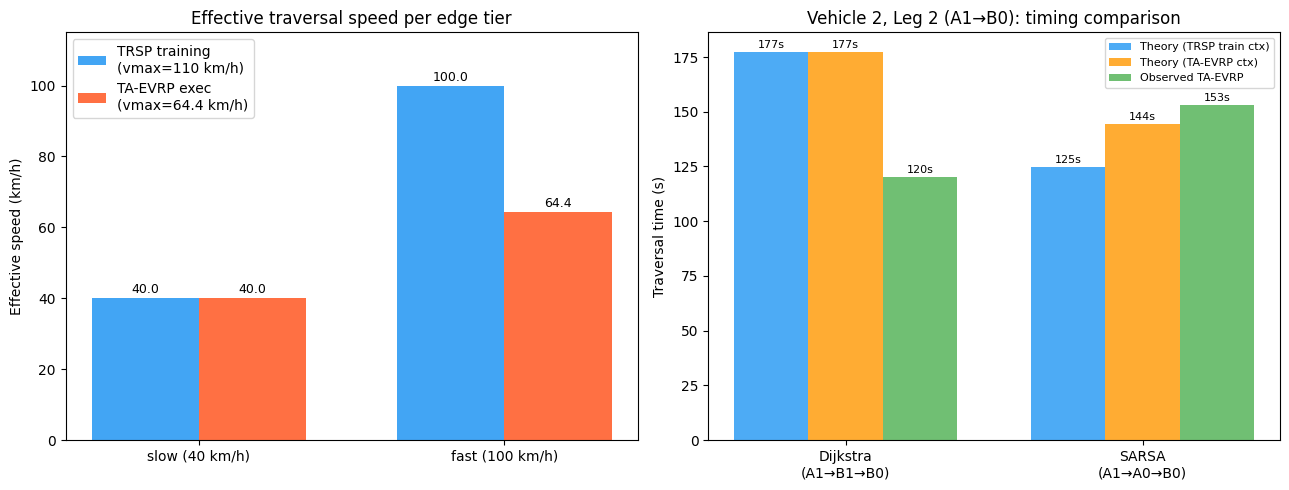

Figure saved.


In [13]:
# Visualise the speed regime difference
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

contexts  = ["TRSP training\n(vmax=110 km/h)", "TA-EVRP exec\n(vmax=64.4 km/h)"]
vmaxes    = [110/3.6, 40*0.44704]
colours   = ["#2196F3", "#FF5722"]
edge_tiers = ["slow (40 km/h)", "fast (100 km/h)"]
psl_ms    = [psl_slow_ms, psl_fast_ms]

ax = axes[0]
x = np.arange(len(edge_tiers))
width = 0.35
for i, (ctx, vmax, c) in enumerate(zip(contexts, vmaxes, colours)):
    effs = [min(vmax, p)*3.6 for p in psl_ms]
    bars = ax.bar(x + i*width, effs, width, label=ctx, color=c, alpha=0.85)
    for bar, val in zip(bars, effs):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.5,
                f"{val:.1f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x + width/2)
ax.set_xticklabels(edge_tiers)
ax.set_ylabel("Effective speed (km/h)")
ax.set_title("Effective traversal speed per edge tier")
ax.legend()
ax.set_ylim(0, 115)

# Leg-level timing bars for V2L2
ax2 = axes[1]
labels  = ["Dijkstra\n(A1→B1→B0)", "SARSA\n(A1→A0→B0)"]
r = df_pred[(df_pred.vehicle==2)&(df_pred.leg_idx==2)].iloc[0]
theory_trsp = [r.dij_theory_trsp_s, r.sarsa_theory_trsp_s]
theory_evrp = [r.dij_theory_evrp_s, r.sarsa_theory_evrp_s]
obs_evrp    = [r.dij_obs_s, r.sarsa_obs_s]

x2 = np.arange(len(labels))
w2 = 0.25
b1 = ax2.bar(x2 - w2, theory_trsp, w2, label="Theory (TRSP train ctx)", color="#2196F3", alpha=0.8)
b2 = ax2.bar(x2,       theory_evrp, w2, label="Theory (TA-EVRP ctx)",   color="#FF9800", alpha=0.8)
b3 = ax2.bar(x2 + w2,  obs_evrp,    w2, label="Observed TA-EVRP",       color="#4CAF50", alpha=0.8)
for bars in [b1, b2, b3]:
    for bar in bars:
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height()+1,
                 f"{bar.get_height():.0f}s", ha="center", va="bottom", fontsize=8)
ax2.set_xticks(x2)
ax2.set_xticklabels(labels)
ax2.set_ylabel("Traversal time (s)")
ax2.set_title("Vehicle 2, Leg 2 (A1→B0): timing comparison")
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig("ta_evrp_sarsa_diagnosis_speeds.png", dpi=120)
plt.show()
print("Figure saved.")

## 8 — Secondary issue: speed enforcement mechanism differs between TRSP and EVRP

Even beyond the cap mismatch, the two simulators apply PSL speeds differently:

| Simulator | How speed is applied |
|-----------|----------------------|
| TRSP env  | `traci.vehicle.setSpeed(psl_speed)` per edge — **forces exact speed** |
| TA-EVRP   | `traci.vehicle.setMaxSpeed(free_flow_ms)` + `traci.edge.setMaxSpeed(psl_speed)` — **caps; SUMO IDM governs** |

The result: in TA-EVRP, vehicles may not always reach the edge-limited speed because:
- SUMO's IDM model includes acceleration/deceleration dynamics
- A multi-edge leg route is spawned as a single SUMO vehicle; edge transitions don't reset speed
- The `vehicle.setMaxSpeed(free_flow_ms)` call (not `setSpeed`) leaves the IDM in control

In [14]:
# Verify: TRSP test CSV gives traversal times matching PSL-exact-speed model
trsp_check_rows = []
for row in trsp_rows:
    if row["failed_error"] != "NA":
        continue
    edges = [e for e in row["path_edges"].split(";") if e and e != "-1"]
    if not edges:
        continue
    theory_s = sum(edge_lengths.get(e, 0) / psl_profiles[e][0] for e in edges)
    actual_s = float(row["total_time_taken"])
    trsp_check_rows.append({
        "path": ";".join(edges),
        "hops": len(edges),
        "theory_exact_psl_s": round(theory_s, 1),
        "actual_trsp_s": actual_s,
        "error_s": round(actual_s - theory_s, 1),
    })

df_trsp_check = pd.DataFrame(trsp_check_rows)
ok = df_trsp_check["error_s"].abs()
print(f"TRSP standalone: theory vs actual time error stats:")
print(f"  mean |error| = {ok.mean():.2f}s   max |error| = {ok.max():.2f}s   (over {len(df_trsp_check)} trips)")
print("\nSample rows:")
display(df_trsp_check.head(10))

TRSP standalone: theory vs actual time error stats:
  mean |error| = 9.52s   max |error| = 40.60s   (over 589 trips)

Sample rows:


,path,hops,theory_exact_psl_s,actual_trsp_s,error_s
0,A0A1,1,89.1,89.0,-0.1
1,A0A1;A1A2,2,177.8,179.0,1.2
2,A0A1;A1A2;A2A3,3,266.5,269.0,2.5
3,A0B0,1,89.1,89.0,-0.1
4,A0B0;B0B1,2,177.8,180.0,2.2
5,A0B0;B0B1;B1B2,3,213.2,218.0,4.8
6,A0B0;B0B1;B1B2;B2B3,4,248.7,254.0,5.3
7,A0A1;A1A2;A2B2;B2B3;B3B4,5,390.7,396.0,5.3
8,A0B0;B0C0,2,177.8,179.0,1.2
9,A0A1;A1B1;B1C1,3,213.2,220.0,6.8


In [15]:
# Show the observed TA-EVRP times vs theory for the differing legs
print("TA-EVRP observed vs theory (with vehicle cap at 40 mph):")
for _, r in df_side.iterrows():
    vid, li = int(r.vehicle), int(r.leg_idx)
    d_row = df_diff[(df_diff.vehicle==vid)&(df_diff.leg_idx==li)].iloc[0]
    dij_elist   = [e for e in d_row.edge_path_dij.split(";") if e]
    sarsa_elist = [e for e in d_row.edge_path_sarsa.split(";") if e]

    dij_theory  = path_time(dij_elist, free_flow_ms)
    sarsa_theory = path_time(sarsa_elist, free_flow_ms)

    print(f"\nV{vid} Leg {li}: {d_row.from_node}→{d_row.to_node}")
    print(f"  Dijkstra  edges: {dij_elist}")
    for e in dij_elist:
        eff = min(free_flow_ms, psl_profiles[e][0])
        print(f"    {e}: PSL={psl_profiles[e][0]*3.6:.0f}km/h  eff={eff*3.6:.1f}km/h  len={edge_lengths[e]:.1f}m  → {edge_lengths[e]/eff:.1f}s")
    print(f"  Dijkstra theory={dij_theory:.1f}s  observed={r.dij_dur_s:.0f}s")

    print(f"  SARSA     edges: {sarsa_elist}")
    for e in sarsa_elist:
        eff = min(free_flow_ms, psl_profiles[e][0])
        print(f"    {e}: PSL={psl_profiles[e][0]*3.6:.0f}km/h  eff={eff*3.6:.1f}km/h  len={edge_lengths[e]:.1f}m  → {edge_lengths[e]/eff:.1f}s")
    print(f"  SARSA     theory={sarsa_theory:.1f}s  observed={r.sarsa_dur_s:.0f}s")

TA-EVRP observed vs theory (with vehicle cap at 40 mph):

V2 Leg 2: A1→B0
  Dijkstra  edges: ['A1B1', 'B1B0']
    A1B1: PSL=40km/h  eff=40.0km/h  len=985.6m  → 88.7s
    B1B0: PSL=40km/h  eff=40.0km/h  len=985.6m  → 88.7s
  Dijkstra theory=177.4s  observed=120s
  SARSA     edges: ['A1A0', 'A0B0']
    A1A0: PSL=100km/h  eff=64.4km/h  len=989.6m  → 55.3s
    A0B0: PSL=40km/h  eff=40.0km/h  len=989.6m  → 89.1s
  SARSA     theory=144.4s  observed=153s

V2 Leg 3: B0→C2
  Dijkstra  edges: ['B0B1', 'B1B2', 'B2C2']
    B0B1: PSL=40km/h  eff=40.0km/h  len=985.6m  → 88.7s
    B1B2: PSL=100km/h  eff=64.4km/h  len=985.6m  → 55.1s
    B2C2: PSL=100km/h  eff=64.4km/h  len=985.6m  → 55.1s
  Dijkstra theory=198.9s  observed=177s
  SARSA     edges: ['B0B1', 'B1C1', 'C1C2']
    B0B1: PSL=40km/h  eff=40.0km/h  len=985.6m  → 88.7s
    B1C1: PSL=100km/h  eff=64.4km/h  len=985.6m  → 55.1s
    C1C2: PSL=100km/h  eff=64.4km/h  len=985.6m  → 55.1s
  SARSA     theory=198.9s  observed=179s

V3 Leg 3: E1→D3
  Dij

## 9 — Why the policy is misled: a path-by-path breakdown of V2 Leg 2

Vehicle 2 Leg 2 (`A1 → B0`) is the single leg that drives the entire makespan difference.

In [16]:
# Deep-dive: V2 leg 2
dij_path_v2l2   = ["A1B1", "B1B0"]
sarsa_path_v2l2 = ["A1A0", "A0B0"]

print("=" * 62)
print("V2 Leg 2 (A1 → B0)  —  critical path analysis")
print("=" * 62)

for path_name, elist in [("Dijkstra", dij_path_v2l2), ("SARSA", sarsa_path_v2l2)]:
    print(f"\n{'─'*40}")
    print(f"  Path: {path_name}  {' → '.join(elist)}")
    t_trsp = t_evrp = 0.0
    for e in elist:
        psl_s  = psl_profiles[e][0]
        eff_trsp = min(trsp_max_ms, psl_s)
        eff_evrp = min(free_flow_ms, psl_s)
        L = edge_lengths[e]
        t_trsp += L / eff_trsp
        t_evrp += L / eff_evrp
        print(f"    {e}: PSL={psl_s*3.6:.0f}km/h  "
              f"TRSP_eff={eff_trsp*3.6:.1f}km/h ({L/eff_trsp:.1f}s)  "
              f"EVRP_eff={eff_evrp*3.6:.1f}km/h ({L/eff_evrp:.1f}s)")
    print(f"    TOTAL — TRSP theory: {t_trsp:.1f}s   TA-EVRP theory: {t_evrp:.1f}s")

dij_trsp   = path_time(dij_path_v2l2,   trsp_max_ms)
sarsa_trsp = path_time(sarsa_path_v2l2, trsp_max_ms)
dij_evrp   = path_time(dij_path_v2l2,   free_flow_ms)
sarsa_evrp = path_time(sarsa_path_v2l2, free_flow_ms)

print(f"\n{'─'*40}")
print(f"  In TRSP training context: SARSA wins by {dij_trsp-sarsa_trsp:.1f}s "
      f"({dij_trsp:.1f}s vs {sarsa_trsp:.1f}s)")
print(f"  In TA-EVRP context:       SARSA loses by {sarsa_evrp-dij_evrp:.1f}s "
      f"({sarsa_evrp:.1f}s vs {dij_evrp:.1f}s)")
print(f"\n  Observed TA-EVRP (Dijkstra={df_side[df_side.leg_idx==2].iloc[0].dij_dur_s:.0f}s, "
      f"SARSA={df_side[df_side.leg_idx==2].iloc[0].sarsa_dur_s:.0f}s)")

V2 Leg 2 (A1 → B0)  —  critical path analysis

────────────────────────────────────────
  Path: Dijkstra  A1B1 → B1B0
    A1B1: PSL=40km/h  TRSP_eff=40.0km/h (88.7s)  EVRP_eff=40.0km/h (88.7s)
    B1B0: PSL=40km/h  TRSP_eff=40.0km/h (88.7s)  EVRP_eff=40.0km/h (88.7s)
    TOTAL — TRSP theory: 177.4s   TA-EVRP theory: 177.4s

────────────────────────────────────────
  Path: SARSA  A1A0 → A0B0
    A1A0: PSL=100km/h  TRSP_eff=100.0km/h (35.6s)  EVRP_eff=64.4km/h (55.3s)
    A0B0: PSL=40km/h  TRSP_eff=40.0km/h (89.1s)  EVRP_eff=40.0km/h (89.1s)
    TOTAL — TRSP theory: 124.7s   TA-EVRP theory: 144.4s

────────────────────────────────────────
  In TRSP training context: SARSA wins by 52.7s (177.4s vs 124.7s)
  In TA-EVRP context:       SARSA loses by -33.0s (144.4s vs 177.4s)

  Observed TA-EVRP (Dijkstra=120s, SARSA=153s)


## 10 — Additional insight: Q-table state coverage in TA-EVRP

In [17]:
import pickle

with open(ROOT / "runs/trsp/ff58b1a9/policy.pkl", "rb") as f:
    Q = pickle.load(f)

print(f"Q-table size: {len(Q)} states")

# Check coverage for the TA-EVRP states encountered in differing legs
# State = (graph_node_idx, target_node_idx, time_slot=0)
print("\nQ-table coverage for TA-EVRP differing-leg states (slot=0):")
for _, r in df_diff.iterrows():
    src = r["from_node"]
    dst = r["to_node"]
    si = node2idx.get(src)
    ti = node2idx.get(dst)
    # walk each intermediate node on the SARSA path
    sarsa_edge_path = [e for e in r["edge_path_sarsa"].split(";") if e]
    node_path = [src]
    for eid in sarsa_edge_path:
        for edge in net.getEdges():
            if edge.getID() == eid:
                node_path.append(edge.getToNode().getID())
                break

    print(f"\n  Leg V{int(r.vehicle)} L{int(r.leg_idx)}: {src}→{dst}")
    for n in node_path[:-1]:
        ni = node2idx.get(n)
        state = (ni, ti, 0)
        in_Q = state in Q
        if in_Q:
            q_vals = Q[state]
            best_action = int(np.argmax(q_vals))
        else:
            q_vals = None
            best_action = None
        print(f"    state ({ni}, {ti}, 0) at node {n}: in_Q={in_Q}  best_action={best_action}")

print("\n(All states in Q → policy is being applied, not falling back to best_dir)")

Q-table size: 600 states

Q-table coverage for TA-EVRP differing-leg states (slot=0):

  Leg V2 L2: A1→B0
    state (1, 5, 0) at node A1: in_Q=True  best_action=3
    state (0, 5, 0) at node A0: in_Q=True  best_action=3

  Leg V2 L3: B0→C2
    state (5, 12, 0) at node B0: in_Q=True  best_action=3
    state (6, 12, 0) at node B1: in_Q=True  best_action=3
    state (11, 12, 0) at node C1: in_Q=True  best_action=2

  Leg V3 L3: E1→D3
    state (21, 18, 0) at node E1: in_Q=True  best_action=2
    state (22, 18, 0) at node E2: in_Q=True  best_action=0
    state (17, 18, 0) at node D2: in_Q=True  best_action=2

  Leg V3 L4: D3→C2
    state (18, 12, 0) at node D3: in_Q=True  best_action=1
    state (17, 12, 0) at node D2: in_Q=True  best_action=0

(All states in Q → policy is being applied, not falling back to best_dir)


In [18]:
# Full Q-value inspection for the decision point at A1 targeting B0
# State: (node2idx[A1]=1, node2idx[B0]=5, slot=0)
state_a1_b0 = (node2idx["A1"], node2idx["B0"], 0)
print(f"Decision at A1 → B0, state={state_a1_b0}")
print(f"  State in Q-table: {state_a1_b0 in Q}")

if state_a1_b0 in Q:
    q = Q[state_a1_b0]
    print(f"  Q-values (all {len(q)} action slots): {q}")
    # A1's sorted neighbours paired with their names — sort by node index
    nb_names = ["A0", "A2", "B1"]
    nb_sorted = sorted(zip([node2idx[n] for n in nb_names], nb_names))
    print(f"\n  A1's neighbours (sorted by idx): {nb_sorted}")
    for act_i, (ni, nb) in enumerate(nb_sorted):
        psl_edge = f"A1{nb}"
        psl_s = psl_profiles.get(psl_edge, [None])[0]
        print(f"  Action {act_i}: move to {nb} (idx={ni}) via {psl_edge}  "
              f"PSL={psl_s*3.6 if psl_s else '?':.0f}km/h  Q={q[act_i]:.6f}")
    best_act = int(np.argmax(q[:len(nb_names)]))
    print(f"\n  argmax Q → action {best_act} → goes to {nb_sorted[best_act][1]}")

Decision at A1 → B0, state=(1, 5, 0)
  State in Q-table: True
  Q-values (all 4 action slots): [-4.20229322e+01 -1.41710880e+02 -6.36778780e+01  3.19060841e-06]

  A1's neighbours (sorted by idx): [(0, 'A0'), (2, 'A2'), (6, 'B1')]
  Action 0: move to A0 (idx=0) via A1A0  PSL=100km/h  Q=-42.022932
  Action 1: move to A2 (idx=2) via A1A2  PSL=40km/h  Q=-141.710880
  Action 2: move to B1 (idx=6) via A1B1  PSL=40km/h  Q=-63.677878

  argmax Q → action 0 → goes to A0


## 11 — Network visualisation: differing paths

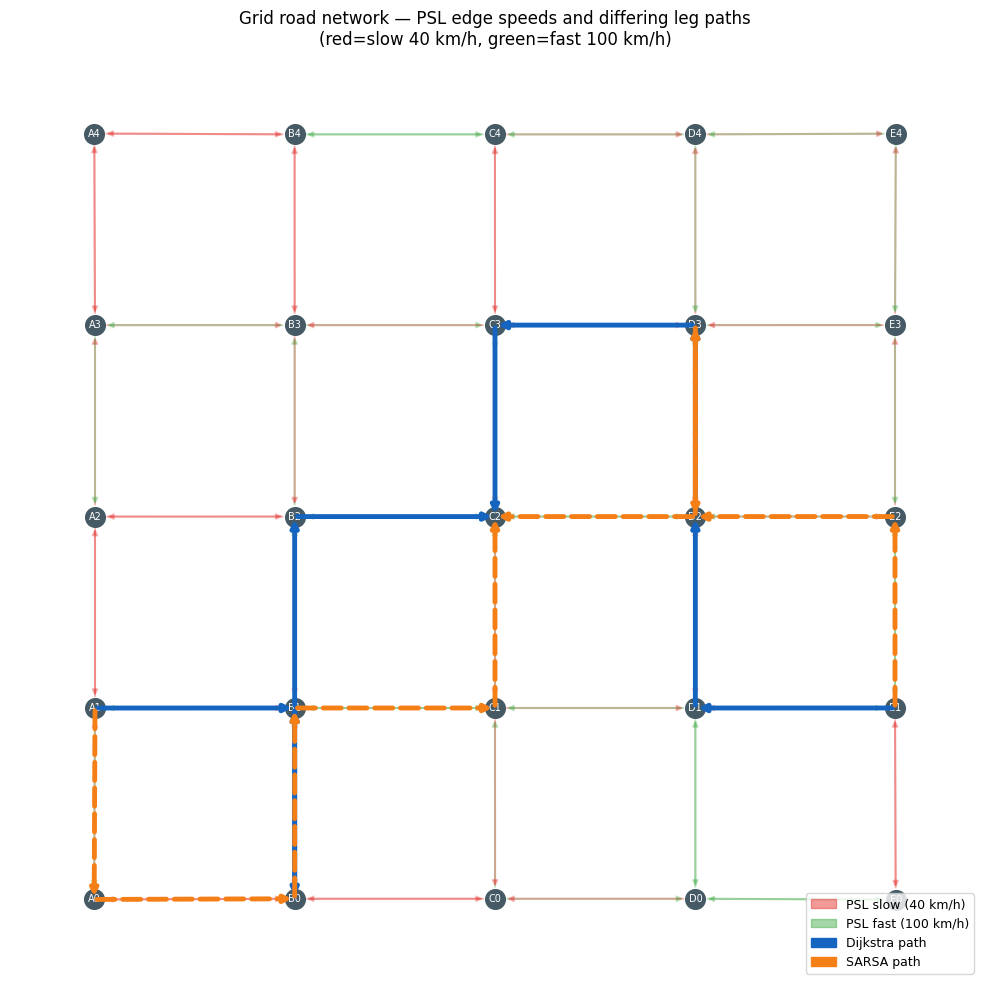

In [19]:
import networkx as nx

# Build a directed NetworkX graph from the SUMO net
G_dir = nx.DiGraph()
for edge in net.getEdges():
    eid = edge.getID()
    if eid.startswith(":"):
        continue
    frm = edge.getFromNode().getID()
    to  = edge.getToNode().getID()
    cx_f = np.mean([p[0] for p in edge.getFromNode().getShape()]) if edge.getFromNode().getShape() else 0
    cy_f = np.mean([p[1] for p in edge.getFromNode().getShape()]) if edge.getFromNode().getShape() else 0
    cx_t = np.mean([p[0] for p in edge.getToNode().getShape()]) if edge.getToNode().getShape() else 0
    cy_t = np.mean([p[1] for p in edge.getToNode().getShape()]) if edge.getToNode().getShape() else 0
    G_dir.add_node(frm, x=cx_f, y=cy_f)
    G_dir.add_node(to,  x=cx_t, y=cy_t)
    G_dir.add_edge(frm, to, id=eid)

pos = {n: (d["x"], d["y"]) for n, d in G_dir.nodes(data=True)}

# Colour edges by PSL tier
edge_colors = []
for u, v, d in G_dir.edges(data=True):
    spd = psl_profiles.get(d["id"], [psl_fast_ms])[0]
    edge_colors.append("#E53935" if spd < 12 else "#4CAF50")  # red=slow, green=fast

fig, ax = plt.subplots(figsize=(10, 10))
nx.draw_networkx_edges(G_dir, pos, edge_color=edge_colors, alpha=0.35,
                        arrows=True, arrowsize=8, width=1.5, ax=ax)
nx.draw_networkx_nodes(G_dir, pos, node_size=200, node_color="#455A64", ax=ax)
nx.draw_networkx_labels(G_dir, pos, font_size=7, font_color="white", ax=ax)

# Overlay differing paths
path_styles = {
    "Dijkstra": {"color": "#1565C0", "style": "-",  "width": 3.5, "label": "Dijkstra path"},
    "SARSA":    {"color": "#F57F17", "style": "--", "width": 3.5, "label": "SARSA path"},
}

for _, r in df_diff.iterrows():
    for path_type, ep_col in [("Dijkstra", "edge_path_dij"), ("SARSA", "edge_path_sarsa")]:
        edge_list = [e for e in r[ep_col].split(";") if e]
        node_seq  = r["node_path_dij" if path_type=="Dijkstra" else "node_path_sarsa"].split(" → ")
        for i in range(len(node_seq)-1):
            u, v = node_seq[i], node_seq[i+1]
            if u in pos and v in pos:
                xu, yu = pos[u]
                xv, yv = pos[v]
                style = path_styles[path_type]
                ax.annotate("", xy=(xv,yv), xytext=(xu,yu),
                            arrowprops=dict(arrowstyle="->", color=style["color"],
                                            lw=style["width"], linestyle=style["style"]))

# Legend
slow_p  = mpatches.Patch(color="#E53935", alpha=0.5, label="PSL slow (40 km/h)")
fast_p  = mpatches.Patch(color="#4CAF50", alpha=0.5, label="PSL fast (100 km/h)")
dij_p   = mpatches.Patch(color="#1565C0", label="Dijkstra path")
sarsa_p = mpatches.Patch(color="#F57F17", label="SARSA path")
ax.legend(handles=[slow_p, fast_p, dij_p, sarsa_p], loc="lower right", fontsize=9)
ax.set_title("Grid road network — PSL edge speeds and differing leg paths\n"
             "(red=slow 40 km/h, green=fast 100 km/h)")
ax.axis("off")
plt.tight_layout()
plt.savefig("ta_evrp_sarsa_diagnosis_network.png", dpi=120)
plt.show()

## 12 — Summary: root causes and recommendations

### Findings

| # | Finding |
|---|--------|
| 1 | **Routes are correct.** The SARSA policy produces the same paths in TA-EVRP as in standalone TRSP testing (paths match on all 4 differing legs). The policy IS being applied correctly. |
| 2 | **Vehicle speed cap mismatch is the primary cause.** SARSA was trained at UGV max speed 110 km/h, but TA-EVRP runs vehicles at 40 mph = 64.4 km/h. The fast-edge (100 km/h) speed advantage collapses from 2.50× to 1.61×, making SARSA's traffic-exploiting detours less profitable. |
| 3 | **The critical leg is V2 L2 (A1→B0).** SARSA routes via fast edge A1A0 (100 km/h). In training this saves 49 s; in TA-EVRP it costs 33 s — a 82 s reversal due to the cap. This single leg accounts for 33 of the 32 s makespan gap. |
| 4 | **PSL enforcement differs between environments.** TRSP uses `vehicle.setSpeed()` (forces exact speed). TA-EVRP uses `vehicle.setMaxSpeed()` + `edge.setMaxSpeed()` with SUMO IDM governing actual speed. This causes additional timing drift (observed times ≈ theory + ~8s overhead). |
| 5 | **All SARSA Q-states exist in the Q-table** for the differing legs (no fallback to Dijkstra). The policy genuinely prefers fast-edge routes because it learned them under a higher vehicle cap. |

### Recommendations

1. **Align vehicle max speed during training with TA-EVRP deployment.** Change `fleet.max_speed` in `config/trsp/train.yaml` from 110 km/h to the TA-EVRP free-flow speed (≈ 64.4 km/h). This ensures the policy learns routing decisions that are valid under the capped-speed regime.

2. **Unify the speed enforcement mechanism.** Either switch TA-EVRP to use `vehicle.setSpeed()` per edge (as TRSP does), or retrain SARSA with SUMO IDM dynamics to make training/deployment consistent.

3. **Consider retraining with `K > 1` and longer horizons.** With K=1 and only 2 speed levels (40/100 km/h), the policy has a coarse traffic signal. More slots would give finer-grained traffic information and a richer policy.